# The sequence family — from Braun et al. (2026) to Lehr, Kumar & Tetzlaff (2024)

A tour of `seqnet.sequences`, the module that generates every training target. All members share one interface
(`rates(t)`, `rates_dt(t)`, `draw_snippet`) and **one clock**: Braun's 8.5-s cycle is the common training timescale.
Parametric Lehr bumps run on it by default (`period`), and the ring network is rescaled to it (`time_scaled`).

**Panels:**
- A: the family on one clock
- B: bump shapes
- C: manifold geometry (Lehr Fig. 1c–e)
- D: speed control by gain (Fig. 4)
- E: shape control by width and E − I (Fig. 2)
- F: subspace rotation by silencing (Fig. 1h–k, 5)
- G: the mechanistic ring network (Fig. 3, S3)
- H: a small FORCE demo: networks trained on four members

Settings in `configs/sequences/sequence_family.yaml`; every entry under `members` is a plain spec for
`build_sequence`, the same dict `ForceConfig.sequence` takes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.paths import repo_root
from seqnet import conventions as cv
from seqnet import sequences as sq
from seqnet.sequences import build_sequence, lehr_bump, measures, natural_period

style()
fig = Figure("sequences", "sequence_family")
cfg = fig.config()
N, T, dt_r = cfg["N"], cfg["period"], cfg["raster_dt"]
members = {name: build_sequence(spec) for name, spec in cfg["members"].items()}


def period_of(s):
    return natural_period(s, np.arange(0, 2 * T, 0.01))


{name: (type(s).__name__, f"period {period_of(s):.3f} s") for name, s in members.items()}

{'braun': ('TravelingBump', 'period 8.500 s'),
 'cosine_k1': ('TravelingBump', 'period 8.500 s'),
 'cosine_k4': ('TravelingBump', 'period 8.500 s'),
 'rectangle_k4': ('TravelingBump', 'period 8.500 s'),
 'sparse_k4': ('TravelingBump', 'period 8.499 s'),
 'network': ('TimeScaled', 'period 8.500 s')}

## Panel A — the family on one clock

Two cycles of each member, neurons in sequence order:
- **braun**: Braun's Gaussian target (a = 0.5, σ = 1.7 s, b = 0).
- **cosine_k1**: Lehr's raised cosine spanning the ring (k = 1).
- **cosine_k4**: the same at k = 4, a quarter of the ring.
- **rectangle_k4**: the morph at ε = 0, the same support as cosine_k4.
- **sparse_k4**: cosine_k4 with 80% of neurons silenced by clustered inhibition.
- **network**: the Lehr ring network, simulated in its own time and rescaled to the 8.5-s cycle.

In [2]:
t = np.arange(0, 2 * T, dt_r)
fig.save("A_family", params=cfg["members"], t=t, **{k: s.rates(t).astype(np.float32) for k, s in members.items()});

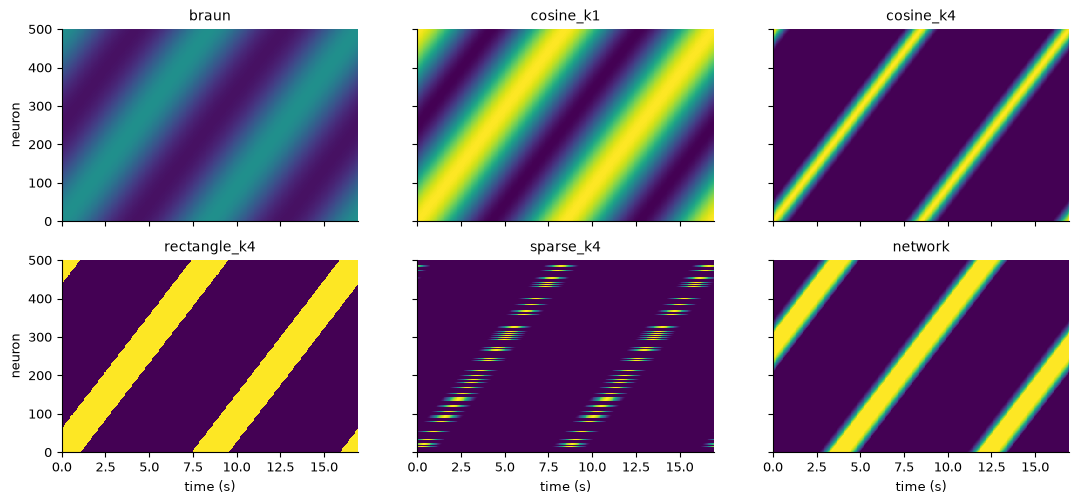

In [3]:
d = fig.load("A_family")
F, axs = plt.subplots(2, 3, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, k in zip(axs.flat, cfg["members"]):
    ax.imshow(d[k], aspect="auto", origin="lower", extent=[d["t"][0], d["t"][-1], 0, N], vmin=0, vmax=1,
              interpolation="nearest")
    ax.set_title(k)
for ax in axs[-1]:
    ax.set_xlabel("time (s)")
for ax in axs[:, 0]:
    ax.set_ylabel("neuron")
fig.savefig("A_family", F); plt.show()

## Panel B — bump shapes

The rates of one neuron over a cycle (peak at t = 0):
- **Left:** Braun's Gaussian and Lehr's raised cosine ψ_k with support N/k (eq. 1).
- **Right:** the morph Φ_{k,ε} (eq. 2–5) at k = 4, from the rectangle (ε = 0) to the cosine (ε → ∞, `null`).

In [4]:
sh = cfg["shapes"]
tb = np.linspace(-T / 2, T / 2, 1001)
prof = {"braun": members["braun"].stationary().profile(tb)}
for k in sh["widths_k"]:
    prof[f"cosine_k{k}"] = lehr_bump(N=N, k=k).stationary().profile(tb)
for e in sh["morph_eps"]:
    prof[f"morph_eps{e}"] = lehr_bump(N=N, k=sh["morph_k"], eps=e).stationary().profile(tb)
fig.save("B_shapes", params=sh, t=tb, **prof);

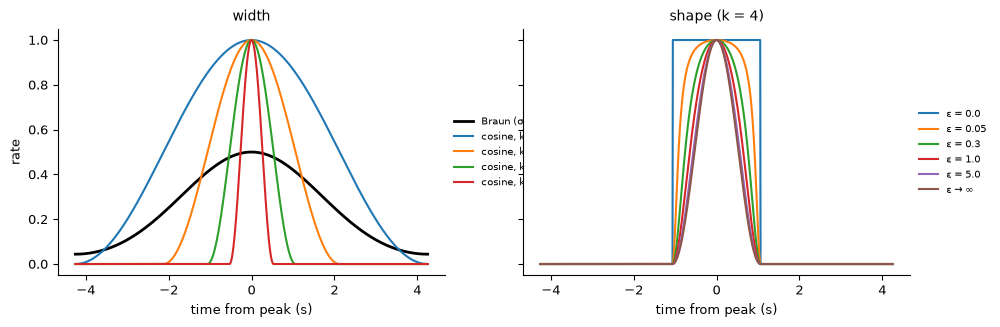

In [5]:
d = fig.load("B_shapes")
F, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
a1.plot(d["t"], d["braun"], "k", lw=2, label="Braun (σ = 1.7 s, a = 0.5)")
for k in sh["widths_k"]:
    a1.plot(d["t"], d[f"cosine_k{k}"], label=f"cosine, k = {k}")
for e in sh["morph_eps"]:
    a2.plot(d["t"], d[f"morph_eps{e}"], label="ε → ∞" if e is None else f"ε = {e}")
a1.set_title("width"); a2.set_title(f"shape (k = {sh['morph_k']})")
for a in (a1, a2):
    a.set_xlabel("time from peak (s)"); a.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5), fontsize=7)
a1.set_ylabel("rate")
fig.savefig("B_shapes", F); plt.show()

## Panel C — manifold geometry (Lehr Fig. 1c–e)

A travelling bump has a circulant covariance, so its principal components are sine–cosine pairs at spatial frequency m
(Lehr Methods). Projected onto the m-th pair, the activity traces a circle traversed m times per cycle.
- **Wide bumps** (k = 1) live in the fundamental plane alone.
- **Narrow bumps** shrink the fundamental circle, grow harmonic circles, and so occupy more dimensions.

In [6]:
g = cfg["geometry"]
tt = np.arange(N) * T / N  # one cycle, one sample per neuron step
x = np.arange(N)


def plane(m):
    # orthonormal sine-cosine pair of the m-th harmonic subspace
    return np.sqrt(2 / N) * np.stack([np.cos(2 * np.pi * m * x / N), np.sin(2 * np.pi * m * x / N)])


def dims90(R):
    s = np.linalg.svd(R - R.mean(1, keepdims=True), compute_uv=False) ** 2
    return int(np.searchsorted(np.cumsum(s) / s.sum(), 0.9) + 1)


radius = np.zeros((len(g["widths_k"]), len(g["harmonics"])))
dims = []
for i, k in enumerate(g["widths_k"]):
    R = lehr_bump(N=N, k=k).rates(tt)
    Rc = R - R.mean(1, keepdims=True)
    radius[i] = [np.linalg.norm(plane(m) @ Rc, axis=0).mean() for m in g["harmonics"]]
    dims.append(dims90(R))
proj = {}
for k in g["example_k"]:
    R = lehr_bump(N=N, k=k).rates(tt)
    for m in g["harmonics"]:
        proj[f"k{k}_m{m}"] = plane(m) @ (R - R.mean(1, keepdims=True))
fig.save("C_geometry", params=g, support=1 / np.array(g["widths_k"]), radius=radius, dims=np.array(dims), **proj);

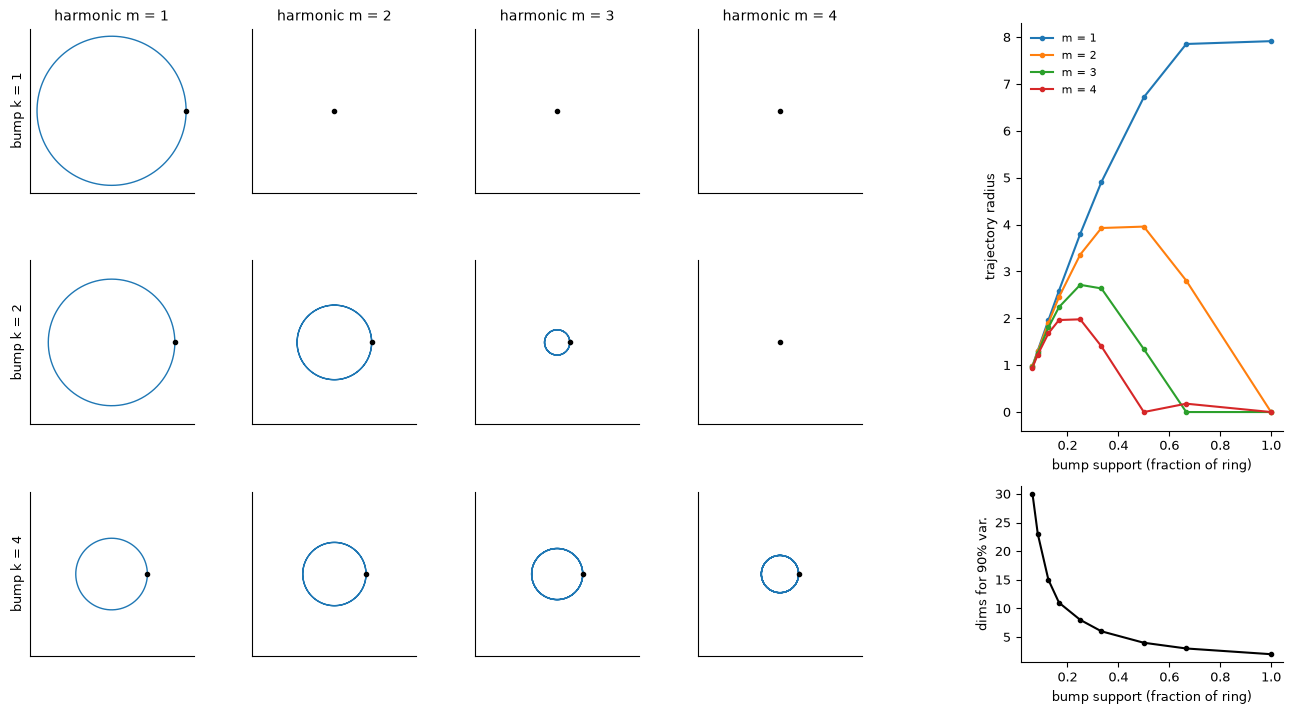

In [7]:
d = fig.load("C_geometry")
nk, nm = len(g["example_k"]), len(g["harmonics"])
F = plt.figure(figsize=(13, 2.4 * nk))
gs = F.add_gridspec(nk, nm + 2, width_ratios=[1] * nm + [0.25, 1.6])
lim = np.abs([d[f"k{k}_m{m}"] for k in g["example_k"] for m in g["harmonics"]]).max() * 1.1
for i, k in enumerate(g["example_k"]):
    for j, m in enumerate(g["harmonics"]):
        ax = F.add_subplot(gs[i, j])
        p = d[f"k{k}_m{m}"]
        ax.plot(p[0], p[1], lw=1); ax.plot(p[0, 0], p[1, 0], "ko", ms=3)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(f"harmonic m = {m}")
        if j == 0:
            ax.set_ylabel(f"bump k = {k}")
ax = F.add_subplot(gs[: max(1, nk // 2 + 1), -1])
for j, m in enumerate(g["harmonics"]):
    ax.plot(d["support"], d["radius"][:, j], "o-", ms=3, label=f"m = {m}")
ax.set_xlabel("bump support (fraction of ring)"); ax.set_ylabel("trajectory radius"); ax.legend(frameon=False)
if nk > 1:
    ax2 = F.add_subplot(gs[nk // 2 + 1:, -1])
    ax2.plot(d["support"], d["dims"], "ko-", ms=3)
    ax2.set_xlabel("bump support (fraction of ring)"); ax2.set_ylabel("dims for 90% var.")
F.tight_layout()
fig.savefig("C_geometry", F); plt.show()

## Panel D — speed control by gain (Lehr Fig. 4)

The bump moves at dc/dt = (N/T)·S(t). The eight gain courses of Fig. 4 run over four cycles (k = 4 cosine):
- step
- exponential decay
- slow and fast exponential growth
- sigmoid
- concave and convex parabolas
- sinusoid

White: the prescribed gain S(t). Dashed: the speed measured from the rates, in the same units. They coincide.

In [8]:
sp = cfg["speed"]
td = np.arange(0, sp["cycles"] * T, dt_r)
out = {"t": td}
for name, gspec in sp["gains"].items():
    R = lehr_bump(N=N, k=sp["k"], gain=gspec).rates(td)
    out[f"{name}_R"] = R.astype(np.float32)
    out[f"{name}_S"] = sq.TIMECOURSES.build(gspec)(td)
    out[f"{name}_v"] = measures.bump_speed(R, dt_r) / (N / T)  # measured speed in units of the gain
fig.save("D_speed", params=sp, **out);

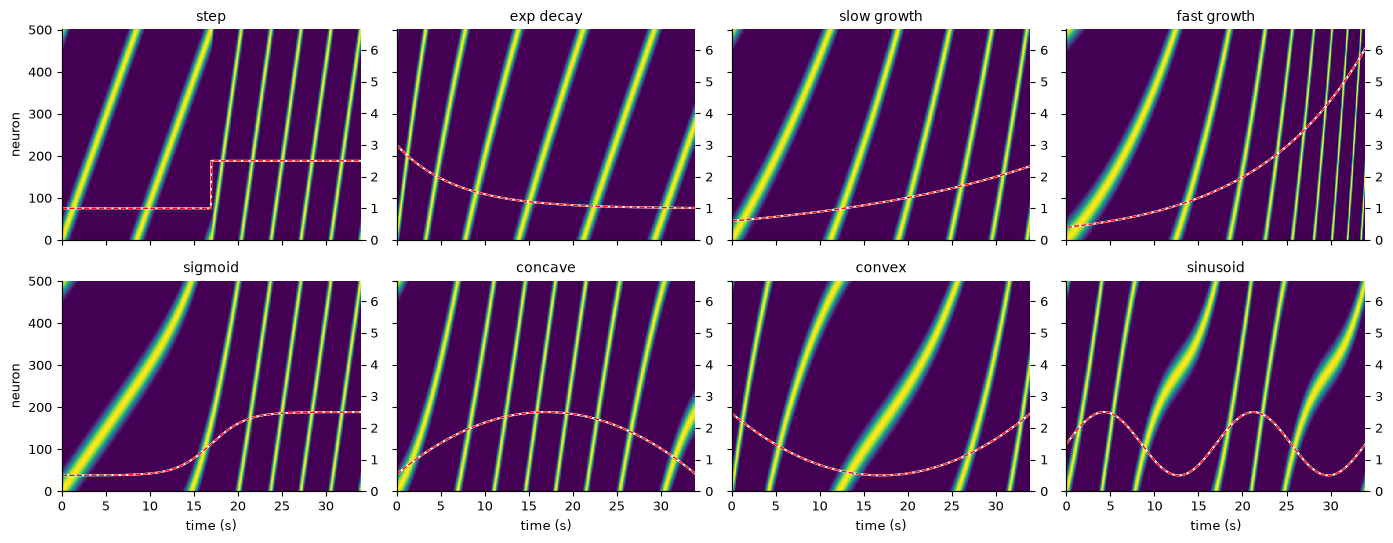

In [9]:
d = fig.load("D_speed")
F, axs = plt.subplots(2, 4, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, name in zip(axs.flat, sp["gains"]):
    ax.imshow(d[f"{name}_R"], aspect="auto", origin="lower", extent=[0, d["t"][-1], 0, N], vmin=0, vmax=1,
              interpolation="nearest")
    tw = ax.twinx()
    tw.plot(d["t"], d[f"{name}_S"], "w", lw=1.5)
    tw.plot(0.5 * (d["t"][1:] + d["t"][:-1]), d[f"{name}_v"], "r--", lw=1)
    tw.set_ylim(0, 1.1 * max(d[f"{nm}_S"].max() for nm in sp["gains"]))
    ax.set_title(name.replace("_", " "))
for ax in axs[-1]:
    ax.set_xlabel("time (s)")
for ax in axs[:, 0]:
    ax.set_ylabel("neuron")
F.tight_layout()
fig.savefig("D_speed", F); plt.show()

## Panel E — shape control (Lehr Fig. 2)

- **Parametric:** a transient pulse in the width scale narrows (blue) or widens (red) the k = 4 bump.
- **Mechanistic:** a transient global E − I current does the same in the ring network. At S = 1 the bump survives
  negative pulses down to about −0.8; stronger inhibition extinguishes it.
- **Both:** the radius of the trajectory in the baseline fundamental plane follows the width (Fig. 2c–d); the speed
  is unchanged.

In [10]:
sc = cfg["shape_control"]
te = np.arange(0, sc["cycles"] * T, dt_r)


def fundamental_basis(R):
    mu = R.mean(1, keepdims=True)
    return np.linalg.svd(R - mu, full_matrices=False)[0][:, :2], mu


B0, mu0 = fundamental_basis(lehr_bump(N=N, k=sc["k"]).rates(np.arange(N) * T / N))
out = {"t": te}
for h in sc["width_pulses"]:
    ws = {"kind": "gaussian_pulse", "baseline": 1.0, "height": h, **sc["pulse"]}
    R = lehr_bump(N=N, k=sc["k"], width_scale=ws).rates(te)
    out[f"w{h}_R"] = R.astype(np.float32)
    out[f"w{h}_radius"] = np.linalg.norm(B0.T @ (R - mu0), axis=0)
    out[f"w{h}_active"] = (R > 0.01).mean(0)
runs = {h: sq.LehrRingNetwork(N=N, duration=3.0, drive={"kind": "gaussian_pulse", "baseline": 0.0, "height": h,
                                                         **sc["drive_pulse"]}).simulate() for h in sc["drives"]}
Bn, mun = fundamental_basis(runs[0.0].samples)
out["t_net"] = runs[0.0].times
for h, q in runs.items():
    out[f"net{h}_R"] = q.samples[:, ::10].astype(np.float32)
    out[f"net{h}_radius"] = np.linalg.norm(Bn.T @ (q.samples - mun), axis=0)
    out[f"net{h}_active"] = (q.samples > 0.01).mean(0)
    out[f"net{h}_speed"] = measures.bump_speed(q.samples, q.dt) / N
fig.save("E_shape", params=sc, **out);

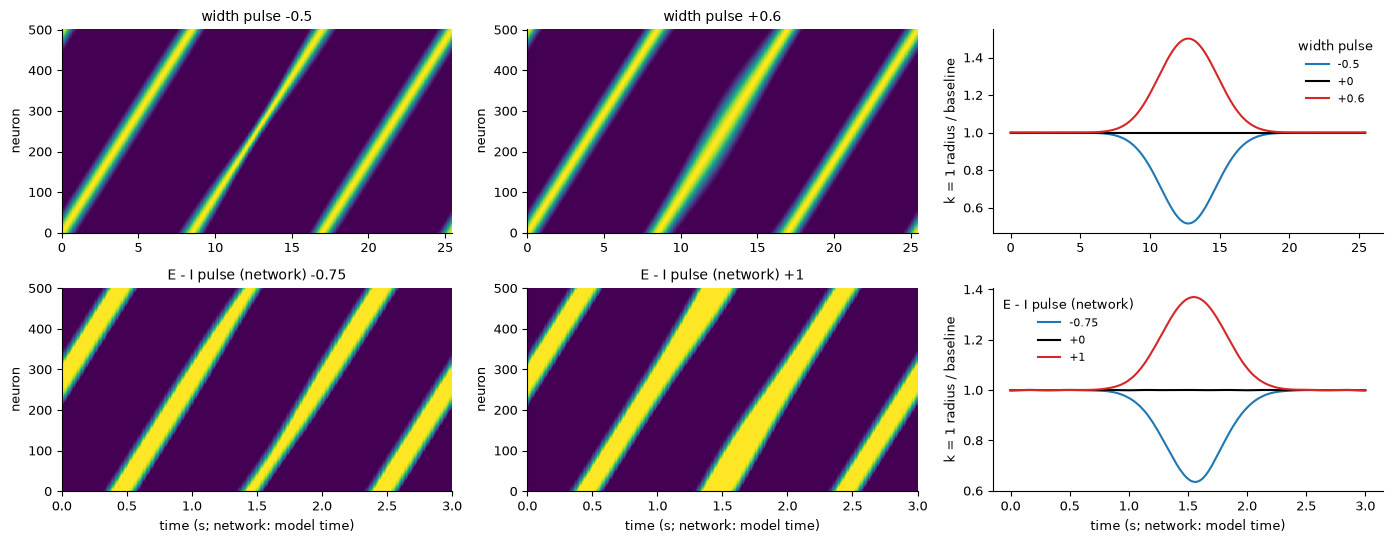

In [11]:
d = fig.load("E_shape")
col = {sc["width_pulses"][0]: "C0", 0.0: "k", sc["width_pulses"][-1]: "C3",
       sc["drives"][0]: "C0", sc["drives"][-1]: "C3"}
F, axs = plt.subplots(2, 3, figsize=(14, 5.5))
for row, (key, hs, t_, label) in enumerate([("w", sc["width_pulses"], d["t"], "width pulse"),
                                             ("net", sc["drives"], d["t_net"], "E - I pulse (network)")]):
    lo, hi = hs[0], hs[-1]
    for ax, h in zip(axs[row, :2], (lo, hi)):
        ext = [t_[0], t_[-1], 0, N]
        ax.imshow(d[f"{key}{h}_R"], aspect="auto", origin="lower", extent=ext, vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(f"{label} {h:+g}"); ax.set_ylabel("neuron")
    ax = axs[row, 2]
    base = d[f"{key}0.0_radius"].mean()
    for h in hs:
        ax.plot(t_, d[f"{key}{h}_radius"] / base, color=col.get(h, "0.5"), label=f"{h:+g}")
    ax.set_ylabel("k = 1 radius / baseline"); ax.legend(frameon=False, title=label)
for ax in axs[-1]:
    ax.set_xlabel("time (s; network: model time)")
F.tight_layout()
fig.savefig("E_shape", F); plt.show()

## Panel F — subspace rotation by silencing (Lehr Fig. 1h–k, 5)

Silencing a random fraction p_inh of neurons projects the sequence onto the remaining ones. Two different silenced
sets give manifolds at a principal angle of about arccos(1 − p_inh) (Lehr Methods; left).
- **Middle:** at p_inh = 0.8, each sequence traces its circle in its own plane, but little in the other's.
- **Right:** switching inhibitory ensembles mid-sequence moves the activity from one subspace to the other.

In [12]:
ss = cfg["subspaces"]
tf = np.arange(N) * T / N


def basis(R):
    return np.linalg.svd(R - R.mean(1, keepdims=True), full_matrices=False)[0][:, :2]


def angle(A, B):
    return np.degrees(np.arccos(min(1.0, np.linalg.svd(A.T @ B, compute_uv=False)[0])))


ns = ss["n_seeds"]
ang = np.zeros((len(ss["p_inh"]), ns * (ns - 1) // 2))
for i, p in enumerate(ss["p_inh"]):
    Bs = [basis(lehr_bump(N=N, k=ss["k"], p_inh=p, seed=s).rates(tf)) for s in range(ns)]
    ang[i] = [angle(Bs[a], Bs[b]) for a in range(ns) for b in range(a + 1, ns)]
p = ss["example_p"]
R1, R2 = (lehr_bump(N=N, k=ss["k"], p_inh=p, seed=s).rates(tf) for s in (0, 1))
B1, B2 = basis(R1), basis(R2)
c = lambda R: R - R.mean(1, keepdims=True)
switch = {"kind": "switching", "switch_times": [ss["switch_cycles"] * T],
          "stages": [{"kind": "random_silencing", "p_inh": p, "seed": s} for s in (0, 1)]}
tsw = np.arange(0, 2 * ss["switch_cycles"] * T, dt_r)
Rsw = lehr_bump(N=N, k=ss["k"], participation=switch).rates(tsw)
fig.save("F_subspaces", params=ss, p_inh=np.array(ss["p_inh"]), angles=ang,
         P11=B1.T @ c(R1), P12=B2.T @ c(R1), P22=B2.T @ c(R2), P21=B1.T @ c(R2),
         t_switch=tsw, R_switch=Rsw.astype(np.float32),
         mag1=np.linalg.norm(B1.T @ (Rsw - R1.mean(1, keepdims=True)), axis=0),
         mag2=np.linalg.norm(B2.T @ (Rsw - R2.mean(1, keepdims=True)), axis=0));

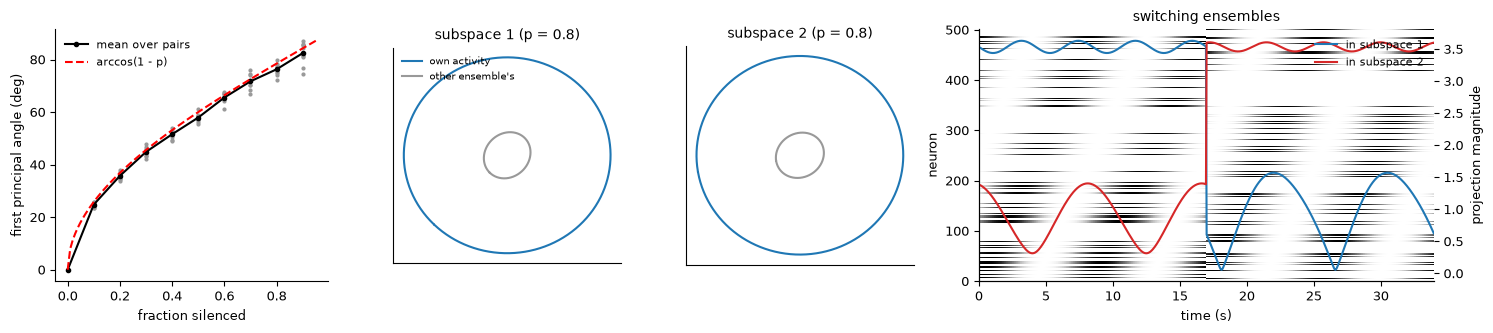

In [13]:
d = fig.load("F_subspaces")
F, axs = plt.subplots(1, 4, figsize=(15, 3.4), gridspec_kw={"width_ratios": [1.2, 1, 1, 2]})
ax = axs[0]
ax.plot(d["p_inh"], d["angles"], ".", color="0.6", ms=4)
ax.plot(d["p_inh"], d["angles"].mean(1), "ko-", ms=3, label="mean over pairs")
pp = np.linspace(0, 0.95, 100)
ax.plot(pp, np.degrees(np.arccos(1 - pp)), "r--", label="arccos(1 - p)")
ax.set_xlabel("fraction silenced"); ax.set_ylabel("first principal angle (deg)"); ax.legend(frameon=False)
for ax, (own, other, title) in zip(axs[1:3], [("P11", "P21", "subspace 1"), ("P22", "P12", "subspace 2")]):
    ax.plot(*d[own], "C0", label="own activity"); ax.plot(*d[other], color="0.6", label="other ensemble's")
    ax.set_aspect("equal"); ax.set_title(f"{title} (p = {ss['example_p']})"); ax.set_xticks([]); ax.set_yticks([])
axs[1].legend(frameon=False, fontsize=7)
ax = axs[3]
ax.imshow(d["R_switch"], aspect="auto", origin="lower", extent=[0, d["t_switch"][-1], 0, N], vmin=0, vmax=1,
          interpolation="nearest", cmap="Greys")
tw = ax.twinx()
tw.plot(d["t_switch"], d["mag1"], "C0", label="in subspace 1"); tw.plot(d["t_switch"], d["mag2"], "C3", label="in subspace 2")
tw.legend(frameon=False, loc="upper right"); tw.set_ylabel("projection magnitude")
ax.set_xlabel("time (s)"); ax.set_ylabel("neuron"); ax.set_title("switching ensembles")
F.tight_layout()
fig.savefig("F_subspaces", F); plt.show()

## Panel G — the mechanistic ring network (Lehr Fig. 3, S3, 2a)

τ dI/dt = −I + P S (W r + E − I), with the state kept in [0, 1] (see `seqnet.sequences.network`: the printed,
unbounded reading gives a speed independent of S).
- **Left:** speed against gain for three kernel shifts. It saturates at one shift per Euler step (Fig. S3: ≈ 19, 38,
  58 rot/s).
- **Middle:** the E − I current sets the bump width, with little effect on speed (Fig. 2a). At S = 1 a constant
  E − I of −0.8 or below extinguishes the bump.
- **Right:** one run with all three controls, rescaled to the 8.5-s training clock:
  - a gain step (speed);
  - a switch to a 70%-silenced ensemble (subspace);
  - an E − I pulse (width).

In [14]:
nw = cfg["network"]
speed = np.zeros((len(nw["shifts"]), len(nw["gains"])))
for i, shift in enumerate(nw["shifts"]):
    for j, S in enumerate(nw["gains"]):
        q = sq.LehrRingNetwork(N=N, shift=shift, gain=S, duration=nw["duration"]).simulate()
        speed[i, j] = measures.bump_speed(q.samples, q.dt).mean() / N
drives = sorted(nw["drives"])
width, dspeed = [], []
for h in drives:
    q = sq.LehrRingNetwork(N=N, drive=h, duration=nw["duration"]).simulate()
    width.append((q.samples[:, -200:] > 0.01).mean())
    dspeed.append(measures.bump_speed(q.samples, q.dt).mean() / N)
ctl = build_sequence({"kind": "time_scaled", "period": T, "sequence": nw["controlled"]})
tc_ = np.arange(0, ctl.duration, dt_r)
fig.save("G_network", params=nw, gains=np.array(nw["gains"]), shifts=np.array(nw["shifts"]), speed=speed,
         drives=np.array(drives), width=np.array(width), drive_speed=np.array(dspeed),
         t_ctl=tc_, R_ctl=ctl.rates(tc_).astype(np.float32), factor=ctl.factor);

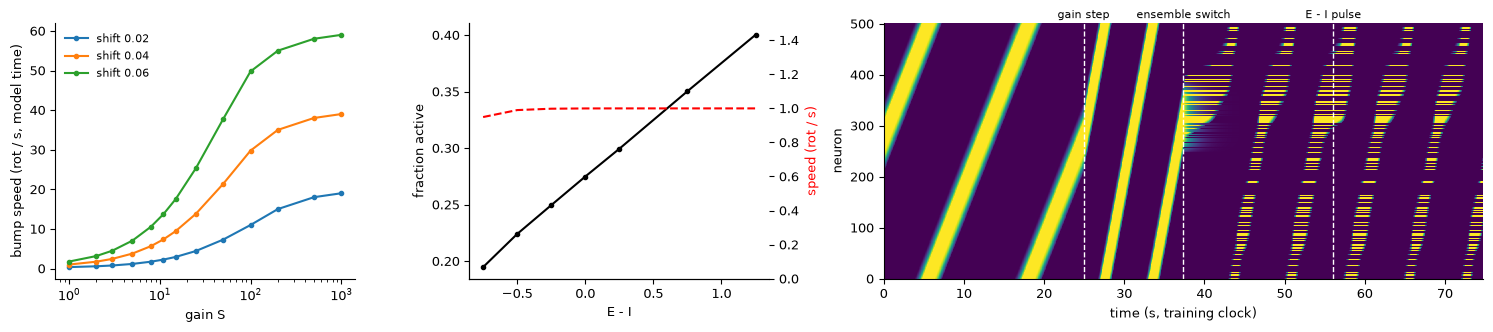

In [15]:
d = fig.load("G_network")
F, axs = plt.subplots(1, 3, figsize=(15, 3.4), gridspec_kw={"width_ratios": [1, 1, 2]})
for i, s in enumerate(d["shifts"]):
    axs[0].semilogx(d["gains"], d["speed"][i], "o-", ms=3, label=f"shift {s:g}")
axs[0].set_xlabel("gain S"); axs[0].set_ylabel("bump speed (rot / s, model time)"); axs[0].legend(frameon=False)
axs[1].plot(d["drives"], d["width"], "ko-", ms=3)
axs[1].set_xlabel("E - I"); axs[1].set_ylabel("fraction active")
tw = axs[1].twinx(); tw.plot(d["drives"], d["drive_speed"], "r--"); tw.set_ylabel("speed (rot / s)", color="r")
tw.set_ylim(0, 1.5 * d["drive_speed"].max())
ax = axs[2]
ax.imshow(d["R_ctl"], aspect="auto", origin="lower", extent=[0, d["t_ctl"][-1], 0, N], vmin=0, vmax=1,
          interpolation="nearest")
c = nw["controlled"]
for tm, lab in [(c["gain"]["t_step"], "gain step"), (c["participation"]["switch_times"][0], "ensemble switch"),
                (c["drive"]["t_peak"], "E - I pulse")]:
    ax.axvline(tm * d["factor"], color="w", ls="--", lw=1); ax.text(tm * d["factor"], N * 1.02, lab, ha="center", fontsize=8)
ax.set_xlabel("time (s, training clock)"); ax.set_ylabel("neuron")
F.tight_layout()
fig.savefig("G_network", F); plt.show()

## Panel H — the sequences as FORCE targets (small demo)

A FORCE network (Braun's setting, N = 501) trained on four members. The runs use the cached runner, in
`results/sequences/runs/`. This is a demo with 3 realizations and 100 + 10 iterations, not final settings.
- **Top:** target and test response.
- **Bottom:** the circulant profile of the mean learned matrix: the connectivity summary the main project
  analyses.

In [16]:
from seqnet.experiments.runner import run_condition
from seqnet.training.config import ForceConfig

tr = cfg["training"]
runs = {}
for name in tr["members"]:
    c = ForceConfig(sequence=cfg["members"][name], n_train=tr["n_train"], n_test=tr["n_test"])
    runs[name] = run_condition(c, tr["n_realizations"], label=f"family_{name}", settings="demo",
                               root=repo_root() / "results" / "sequences" / "runs")
out = {}
for name, r in runs.items():
    S = r.summary
    out[f"{name}_target"], out[f"{name}_resp"] = S["f_target0"], S["R_test0"]
    out[f"{name}_corr"] = S["corr"]
    out[f"{name}_d"], out[f"{name}_cp"] = cv.centred_profile(cv.profile_from_matrix(S["mean_W"]))
fig.save("H_training", params=tr, **out)
{name: round(float(r.summary["corr"][:, -tr["n_test"]:].mean()), 3) for name, r in runs.items()}

{'braun': 0.856, 'cosine_k4': 0.831, 'sparse_k4': 0.836, 'network': 0.921}

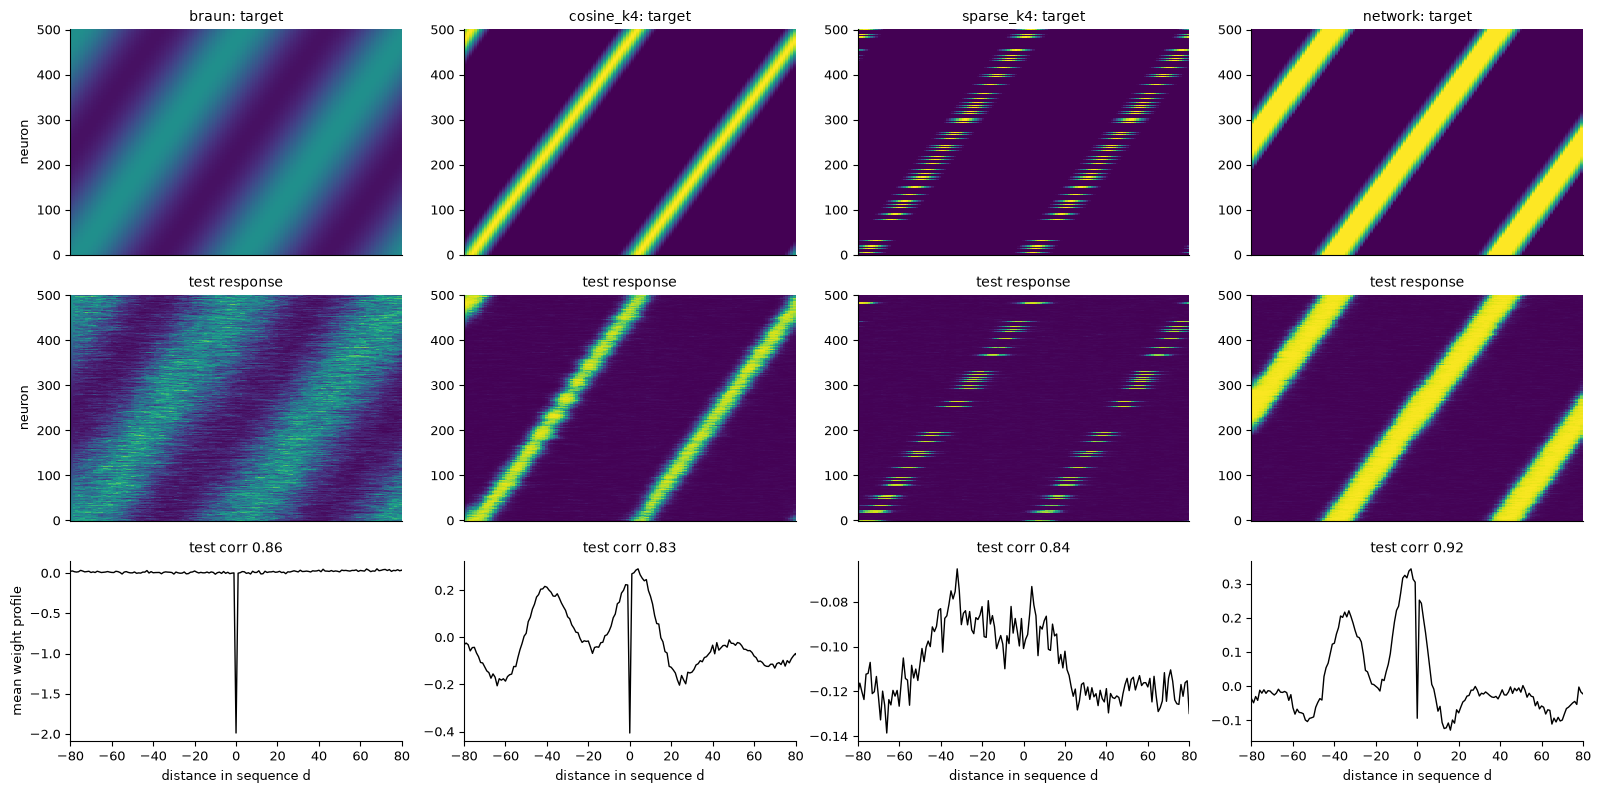

In [17]:
d = fig.load("H_training")
names = tr["members"]
F, axs = plt.subplots(3, len(names), figsize=(4 * len(names), 8), gridspec_kw={"height_ratios": [1, 1, 0.8]})
for j, name in enumerate(names):
    for i, (key, lab) in enumerate([("target", "target"), ("resp", "test response")]):
        axs[i, j].imshow(d[f"{name}_{key}"], aspect="auto", origin="lower", vmin=0, vmax=1, interpolation="nearest")
        axs[i, j].set_title(f"{name}: {lab}" if i == 0 else lab); axs[i, j].set_xticks([])
    ax = axs[2, j]
    ax.plot(d[f"{name}_d"], d[f"{name}_cp"], "k", lw=1)
    ax.set_xlim(-80, 80); ax.set_xlabel("distance in sequence d"); ax.set_title(f"test corr {d[f'{name}_corr'][:, -tr['n_test']:].mean():.2f}")
axs[0, 0].set_ylabel("neuron"); axs[1, 0].set_ylabel("neuron"); axs[2, 0].set_ylabel("mean weight profile")
F.tight_layout()
fig.savefig("H_training", F); plt.show()

## Acceptance checks

In [18]:
A, C, D, E, Fs, G, H = (fig.load(p) for p in ("A_family", "C_geometry", "D_speed", "E_shape", "F_subspaces",
                                              "G_network", "H_training"))
lo = [float(A[k].min()) for k in cfg["members"]]
hi = [float(A[k].max()) for k in cfg["members"]]
rel_v = max(np.median(np.abs(D[f"{n}_v"] / (0.5 * (D[f"{n}_S"][1:] + D[f"{n}_S"][:-1])) - 1)) for n in sp["gains"])
dev = np.abs(Fs["angles"].mean(1) - np.degrees(np.arccos(1 - Fs["p_inh"])))
sat = G["speed"][:, -1]
w_lo, w_hi = sc["width_pulses"][0], sc["width_pulses"][-1]
r_ratio = (E[f"w{w_lo}_radius"].min() / E["w0.0_radius"].mean(), E[f"w{w_hi}_radius"].max() / E["w0.0_radius"].mean())
corr = {n: round(float(H[f"{n}_corr"][:, -tr["n_test"]:].mean()), 3) for n in tr["members"]}
fig.checks([
    {"item": "A: every member's rates lie in [0, 1]", "value": (min(lo), max(hi)), "passed": min(lo) >= 0 and max(hi) <= 1},
    {"item": "A: network rescaled to the training period (s)", "value": round(period_of(members["network"]), 6),
     "passed": abs(period_of(members["network"]) - T) < 1e-3 * T},
    {"item": "C: a k = 1 bump spans one plane (dims for 90% variance)", "value": int(C["dims"][0]), "passed": int(C["dims"][0]) == 2},
    {"item": "C: dimensionality rises as the bump narrows", "value": C["dims"].tolist(),
     "passed": bool(np.all(np.diff(C["dims"]) >= 0) and C["dims"][-1] > C["dims"][0])},
    {"item": "D: measured speed follows the gain (worst median relative error)", "value": float(rel_v), "passed": rel_v < 0.01},
    {"item": "E: width pulses shrink / grow the k = 1 radius (min, max vs baseline)", "value": r_ratio,
     "passed": r_ratio[0] < 0.9 and r_ratio[1] > 1.05},
    {"item": "F: principal angle vs arccos(1 - p) (max deviation of the mean, deg)", "value": float(dev.max()), "passed": dev.max() < 5},
    {"item": "G: saturation speeds at S = 1000 (rot/s; Fig. S3 about 19 / 38 / 58)", "value": np.round(sat, 1).tolist(),
     "passed": bool(np.allclose(sat, [19, 38.5, 58.5], rtol=0.05))},
    {"item": "G: E - I widens the bump monotonically", "value": np.round(G["width"], 3).tolist(),
     "passed": bool(np.all(np.diff(G["width"]) > 0))},
    {"item": "H: FORCE test correlation per member (demo settings)", "value": corr, "passed": None},
])

[PASS] A: every member's rates lie in [0, 1]: (0.0, 1.0)
[PASS] A: network rescaled to the training period (s): 8.499983
[PASS] C: a k = 1 bump spans one plane (dims for 90% variance): 2
[PASS] C: dimensionality rises as the bump narrows: [2, 3, 4, 6, 8, 11, 15, 23, 30]
[PASS] D: measured speed follows the gain (worst median relative error): 1.0918165977757965e-05
[PASS] E: width pulses shrink / grow the k = 1 radius (min, max vs baseline): (np.float64(0.5154260855903058), np.float64(1.5011127850158872))
[PASS] F: principal angle vs arccos(1 - p) (max deviation of the mean, deg): 2.173697021256018
[PASS] G: saturation speeds at S = 1000 (rot/s; Fig. S3 about 19 / 38 / 58): [19.0, 39.0, 59.0]
[PASS] G: E - I widens the bump monotonically: [0.195, 0.224, 0.25, 0.275, 0.299, 0.35, 0.4]
[info] H: FORCE test correlation per member (demo settings): {'braun': 0.856, 'cosine_k4': 0.831, 'sparse_k4': 0.836, 'network': 0.921}


WindowsPath('C:/Users/max/Documents/phd-work/results/sequences/data/sequence_family/acceptance.json')